Experiment with random pose and A sort of retrieval

In [1]:
import sys
sys.path.append("/Experiments/riccardop02")

import torch
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from transformers import AutoModel, AutoImageProcessor

from JEPA.Essential.path import RENDERS
import plotly.io as pio #; pio.renderers.default = "notebook"

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

MODEL_NAME = "facebook/dinov2-base"

processor = AutoImageProcessor.from_pretrained(MODEL_NAME)
model = AutoModel.from_pretrained(MODEL_NAME).to(device).eval()

# spegniamo i gradienti: facciamo solo inferenza, encoder frozen
for p in model.parameters():
    p.requires_grad_(False)

n_params = sum(p.numel() for p in model.parameters())
print(f"{MODEL_NAME} caricato — {n_params/1e6:.1f}M parametri")
print("patch size:", model.config.patch_size, "| hidden dim:", model.config.hidden_size)

/Experiments/riccardop02/poseJepa/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cuda


Loading weights: 100%|██████████| 223/223 [00:00<00:00, 8173.53it/s]


facebook/dinov2-base caricato — 86.6M parametri
patch size: 14 | hidden dim: 768


In [2]:
import torch.nn.functional as F

@torch.no_grad()
def extract_features2(img, layers=[-1], token="pool", grid=2,
                     norm_mode="global", normalize=True):
    """
    token="pool" -> spatial pooling su griglia grid x grid (default 2x2)
    norm_mode:
        "global" -> L2 sul descrittore finale concatenato
        "cell"   -> L2 su ogni cella PRIMA di concatenare
    """
    inputs = processor(images=img, return_tensors="pt").to(device)
    hs = model(**inputs, output_hidden_states=True).hidden_states

    parts = []
    for L in layers:
        h = hs[L][0]                              # (n_token, 768)
        if token == "cls":
            v = h[0]
        elif token == "ptc":
            v = h[1:].flatten()
        elif token == "pool":
            P = h[1:]                             # (256, 768)
            side = int(P.shape[0] ** 0.5)         # 16
            g = P.reshape(side, side, -1)         # (16, 16, 768)
            step = side // grid                   # quante patch per cella
            cells = []
            for r in range(grid):
                for c in range(grid):
                    cell = g[r*step:(r+1)*step, c*step:(c+1)*step, :].mean(dim=(0, 1))
                    if norm_mode == "cell":
                        cell = F.normalize(cell, dim=-1)
                    cells.append(cell)
            v = torch.cat(cells)                  # (grid*grid*768,)

        elif token == "hybrid":
            cls = F.normalize(h[0], dim=-1)                     # texture/semantica
            P = h[1:]
            side = int(P.shape[0] ** 0.5)
            gr = P.reshape(side, side, -1)
            step = side // grid
            cells = [gr[r*step:(r+1)*step, c*step:(c+1)*step, :].mean(dim=(0, 1))
                     for r in range(grid) for c in range(grid)]
            pool = F.normalize(torch.cat(cells), dim=-1)         # geometria
            v = torch.cat([cls, pool])                           # texture + forma

        else:
            raise ValueError(token)

        if normalize and token not in ("hybrid") and not (token == "pool" and norm_mode == "cell"):
            v = F.normalize(v, dim=-1)
        parts.append(v)
    return torch.cat(parts, dim=-1)

print("Extract Features Ready!")

Extract Features Ready!


In [4]:
dummy = Image.new("RGB", (224, 224), (128, 128, 128))
emb = extract_features2(dummy, layers=[-1], token="pool")
print("Dimension Descriptor:", emb.shape)       

Dimension Descriptor: torch.Size([3072])


Calcolo embedding di 800 immagini...


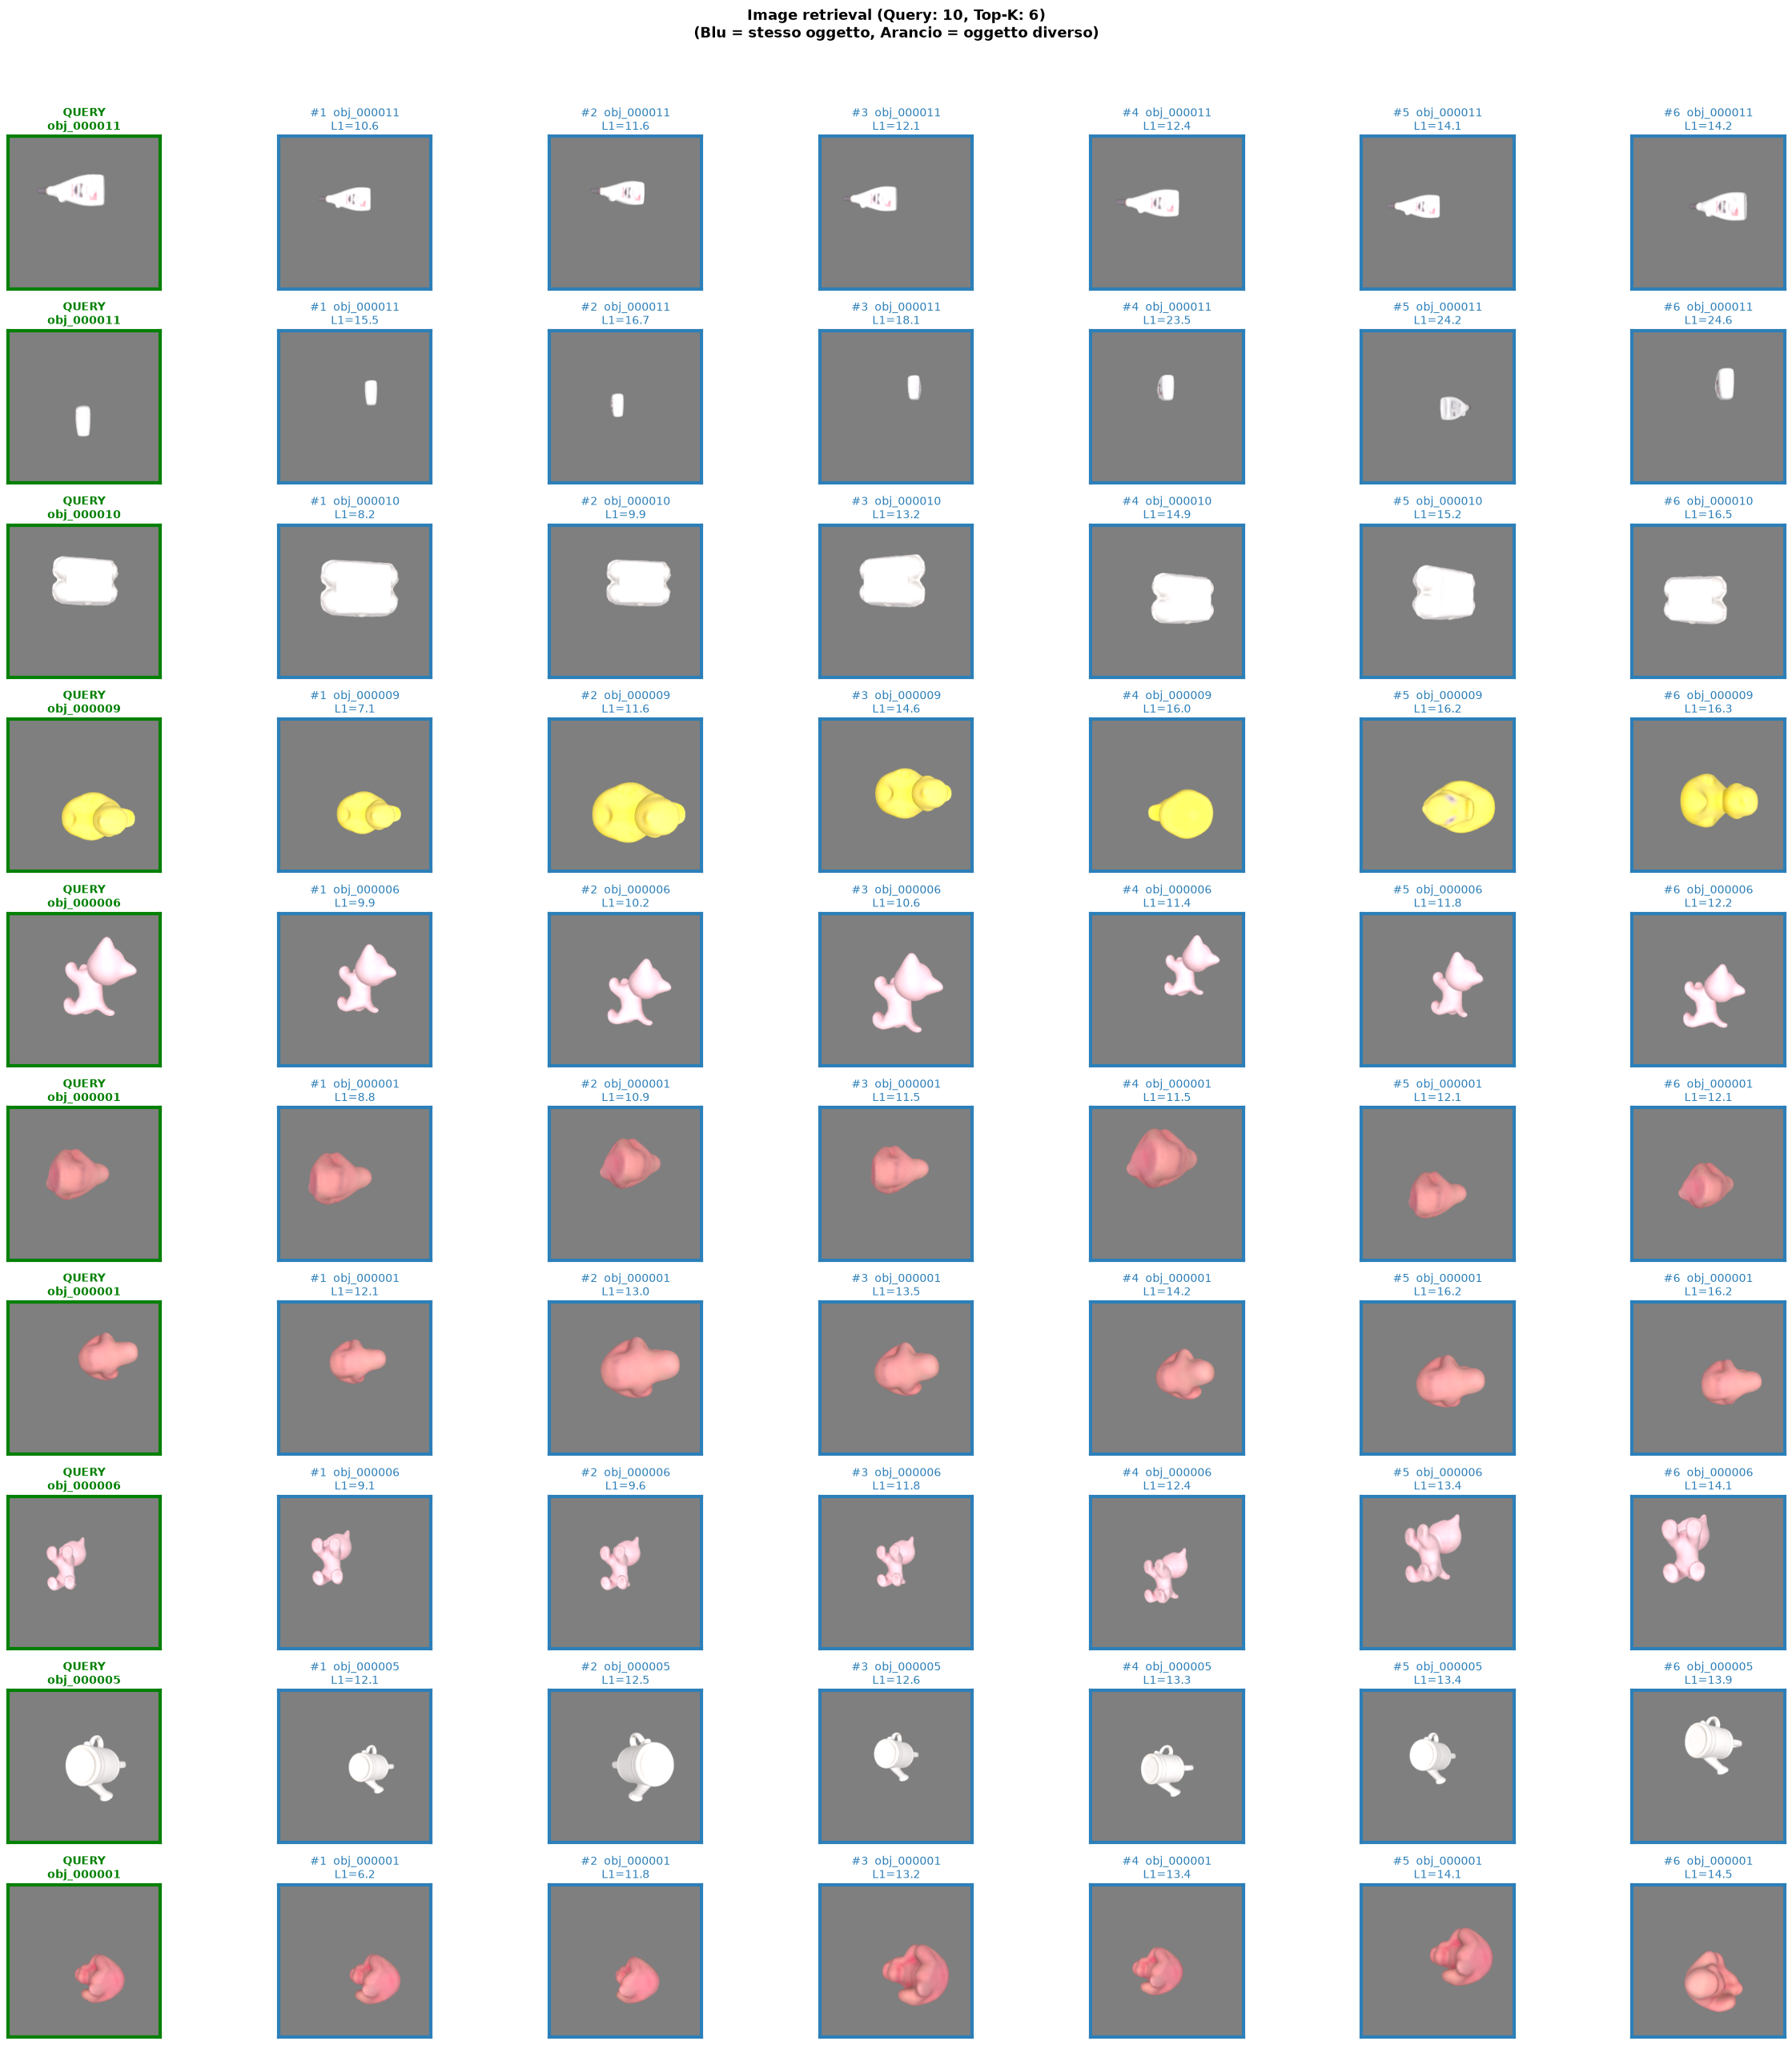

In [ ]:

DATASET = "lmo"          
TOKEN   = "pool"
GRID    = 2
SEED    = 0

# --- NUOVI PARAMETRI CONFIGURABILI ---
NUM_QUERIES = 10  # Numero di oggetti/query da visualizzare (righe)
TOP_K       = 6  # Numero di output più simili da restituire (colonne extra)

df = pd.read_csv(RENDERS / DATASET / "gt_poses.csv").reset_index(drop=True)

# --- Costruisci la galleria: embedding di TUTTE le immagini ---
print(f"Calcolo embedding di {len(df)} immagini...")
gallery = []
for i in range(len(df)):
    e = extract_features2(Image.open(RENDERS / df.iloc[i]["image"]).convert("RGB"),
                          token=TOKEN, grid=GRID)
    gallery.append(e)
gallery = torch.stack(gallery)        # (N, D)

# --- Estrazione query casuali ---
rng = np.random.default_rng(SEED)
queries = rng.choice(len(df), size=NUM_QUERIES, replace=False)

# --- Impostazione dinamica della griglia ---
# Righe = NUM_QUERIES
# Colonne = 1 (Query) + TOP_K (Risultati)
# Figsize si adatta dinamicamente per evitare immagini schiacciate
fig, axes = plt.subplots(NUM_QUERIES, TOP_K + 1, figsize=(3.5 * (TOP_K + 1), 2.5 * NUM_QUERIES))

# Gestione del caso limite in cui NUM_QUERIES = 1 (matplotlib restituisce un array 1D)
if NUM_QUERIES == 1:
    axes = np.expand_dims(axes, axis=0)

for r, q in enumerate(queries):
    # Distanza L1 della query da TUTTA la galleria
    d = torch.abs(gallery - gallery[q]).sum(dim=1)
    d[q] = float("inf")               # Escludi se stessa
    
    # Prendi solo i primi TOP_K risultati
    top = torch.argsort(d)[:TOP_K].cpu().numpy()

    # Colonna 0 = Query
    qrow = df.iloc[q]
    axes[r, 0].imshow(Image.open(RENDERS / qrow["image"]).convert("RGB"))
    axes[r, 0].set_title(f"QUERY\n{qrow['object']}", fontsize=10, color="green", fontweight="bold")
    for s in axes[r, 0].spines.values(): 
        s.set_color("green")
        s.set_linewidth(3)
    axes[r, 0].set_xticks([])
    axes[r, 0].set_yticks([])

    # Colonne 1 fino a TOP_K = i più vicini
    for k, idx in enumerate(top):
        row = df.iloc[idx]
        
        # Verde se stesso oggetto della query, arancio se diverso
        same = (row["object"] == qrow["object"])
        col = "#2c7fb8" if same else "#d95f0e"
        
        axes[r, k+1].imshow(Image.open(RENDERS / row["image"]).convert("RGB"))
        axes[r, k+1].set_title(f"#{k+1}  {row['object']}\nL1={d[idx]:.1f}", fontsize=10, color=col)
        for s in axes[r, k+1].spines.values(): 
            s.set_color(col)
            s.set_linewidth(3)
        axes[r, k+1].set_xticks([])
        axes[r, k+1].set_yticks([])

# Titolo generale
plt.suptitle(
    f"Image retrieval\n", 
    y=1.02, fontsize=13, fontweight="bold"
)

plt.tight_layout()
plt.show()

# ENERGIA

In [14]:
import pandas as pd

DATASET = "ycbv"      # render sulla griglia 2 assi
OBJ = "obj_000015"
TOKEN = "pool"
N = 15                      # n_per_axis usato in generazione
SPAN = 90

df = pd.read_csv(RENDERS / DATASET / "gt_poses.csv")
df = df[df.object==OBJ].sort_values("pose_idx").reset_index(drop=True)

# embedding di tutte le pose della griglia
embs = [extract_features2(Image.open(RENDERS/df.loc[i,"image"]).convert("RGB"), token=TOKEN)
        for i in range(len(df))]

# target = posa centrale (rx=0, ry=0) -> indice centrale della griglia
target = (N*N)//2
e_target = embs[target]

# energia su tutta la griglia, rimodellata in matrice N x N
energy = np.array([torch.abs(e_target - e).sum().item() for e in embs]).reshape(N, N)

angs = np.linspace(-SPAN, SPAN, N)
AX, AY = np.meshgrid(angs, angs)

fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection="3d")
surf = ax.plot_surface(AX, AY, energy, cmap="viridis", edgecolor="none", alpha=0.9)
ax.set_xlabel("rotazione X (°)"); ax.set_ylabel("rotazione Y (°)")
ax.set_zlabel("Energia E(p)")
ax.set_title(f"Paesaggio dell'energia 3D — {OBJ}")
ax.scatter([0],[0],[energy[N//2,N//2]], color="red", s=80, label="posa vera")
fig.colorbar(surf, shrink=0.5)
ax.legend()
plt.show()

IndexError: list index out of range

# SIM TO REAL -- GAP (If we move to occlusion and real scene it reduces performance????)
